# Hull Tactical - Market Prediction | Baseline Solo Notebook



In [1]:
# Install dependencies (if not already installed)
!pip install lightgbm pandas numpy scikit-learn matplotlib --quiet


[notice] A new release of pip available: 22.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Imports
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


# Load Data

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print(train.head())


Train shape: (8990, 98)
Test shape: (10, 99)
   date_id  D1  D2  D3  D4  D5  D6  D7  D8  D9  ...  V3  V4  V5  V6  V7  V8  \
0        0   0   0   0   1   1   0   0   0   1  ... NaN NaN NaN NaN NaN NaN   
1        1   0   0   0   1   1   0   0   0   1  ... NaN NaN NaN NaN NaN NaN   
2        2   0   0   0   1   0   0   0   0   1  ... NaN NaN NaN NaN NaN NaN   
3        3   0   0   0   1   0   0   0   0   0  ... NaN NaN NaN NaN NaN NaN   
4        4   0   0   0   1   0   0   0   0   0  ... NaN NaN NaN NaN NaN NaN   

   V9  forward_returns  risk_free_rate  market_forward_excess_returns  
0 NaN        -0.002421        0.000301                      -0.003038  
1 NaN        -0.008495        0.000303                      -0.009114  
2 NaN        -0.009624        0.000301                      -0.010243  
3 NaN         0.004662        0.000299                       0.004046  
4 NaN        -0.011686        0.000299                      -0.012301  

[5 rows x 98 columns]


In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Data Preprocessing

# Drop columns that are all NaN or constant
drop_cols = [c for c in train.columns if train[c].nunique() <= 1]
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols, errors="ignore")

# Fill NaNs: forward fill first, then median fill 
train = train.fillna(method='ffill').fillna(train.median())
test = test.fillna(method='ffill').fillna(test.median())

# Identify numeric features 
target_col = "market_forward_excess_returns"
exclude_cols = ["date_id", "forward_returns", "risk_free_rate", target_col]
num_features = [c for c in train.columns if c not in exclude_cols]

In [ ]:
# Rolling Features 

train_sorted = train.sort_values("date_id").reset_index(drop=True)

def add_rolling_features(df, features, windows=[5, 10, 20]):
    df_new = df.copy()
    for w in windows:
        for f in features:
            if df_new[f].dtype != "O":
                df_new[f"{f}_rollmean_{w}"] = df_new[f].rolling(w).mean()
                df_new[f"{f}_rollstd_{w}"] = df_new[f].rolling(w).std()
    return df_new

train_feat = add_rolling_features(train_sorted, num_features)
train_feat = train_feat.fillna(train_feat.median())

# We can’t do rolling on test since it’s too short (10 rows) — fill with last known train values
test_feat = test.copy()
for col in train_feat.columns:
    if col not in test_feat.columns:
        test_feat[col] = train_feat[col].iloc[-1]
print("Train features shape:", train_feat.shape)
print("Test features shape:", test_feat.shape)

Train features shape: (8990, 662)
Test features shape: (10, 666)


In [5]:
# Prepare Training Matrices

features = [c for c in train_feat.columns if c not in exclude_cols]
X = train_feat[features]
y = train_feat[target_col]
X_test = test_feat[features]
print("Final feature set shape:", X.shape)
print("Final test feature set shape:", X_test.shape)

Final feature set shape: (8990, 658)
Final test feature set shape: (10, 658)


In [6]:
# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

In [7]:
from lightgbm import early_stopping, log_evaluation

# Time Series Split Cross-Validation 

tscv = TimeSeriesSplit(n_splits=5)
oof_preds = np.zeros(len(X))
models = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_scaled, y)):
    X_train, y_train = X_scaled[train_idx], y.iloc[train_idx]
    X_val, y_val = X_scaled[val_idx], y.iloc[val_idx]
    
    train_set = lgb.Dataset(X_train, y_train)
    val_set = lgb.Dataset(X_val, y_val)
    
    params = {
        "objective": "regression",
        "metric": "rmse",
        "boosting_type": "gbdt",
        "num_leaves": 64,
        "learning_rate": 0.01,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "seed": 42,
        "verbosity": -1,
        "n_jobs": -1,
    }
    
    model = lgb.train(
        params=params,
        train_set=train_set,
        valid_sets=[train_set, val_set],
        num_boost_round=8000,
        callbacks=[
            early_stopping(stopping_rounds=200),
            log_evaluation(period=500)
        ]
    )
    
    oof_preds[val_idx] = model.predict(X_val, num_iteration=model.best_iteration)
    models.append(model)
    mse = mean_squared_error(y_val, oof_preds[val_idx])
rmse = np.sqrt(mse)
print(f"Fold {fold+1} RMSE: {rmse:.6f}")

Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[2]	training's rmse: 0.00730818	valid_1's rmse: 0.0120901
Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[56]	training's rmse: 0.00896112	valid_1's rmse: 0.0097966
Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[9]	training's rmse: 0.0097688	valid_1's rmse: 0.0133032
Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[16]	training's rmse: 0.0105962	valid_1's rmse: 0.00819282
Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[1]	training's rmse: 0.0103791	valid_1's rmse: 0.0113879
Fold 5 RMSE: 0.011388


In [8]:
# Evaluate Local Sharpe-like Metric

def sharpe_ratio(pred, true):
    returns = pred * true
    mean_r = np.mean(returns)
    std_r = np.std(returns)
    return mean_r / std_r if std_r != 0 else 0

score = sharpe_ratio(oof_preds, y.values)
print(f"\nLocal Pseudo-Sharpe Score: {score:.6f}")


Local Pseudo-Sharpe Score: 0.021832


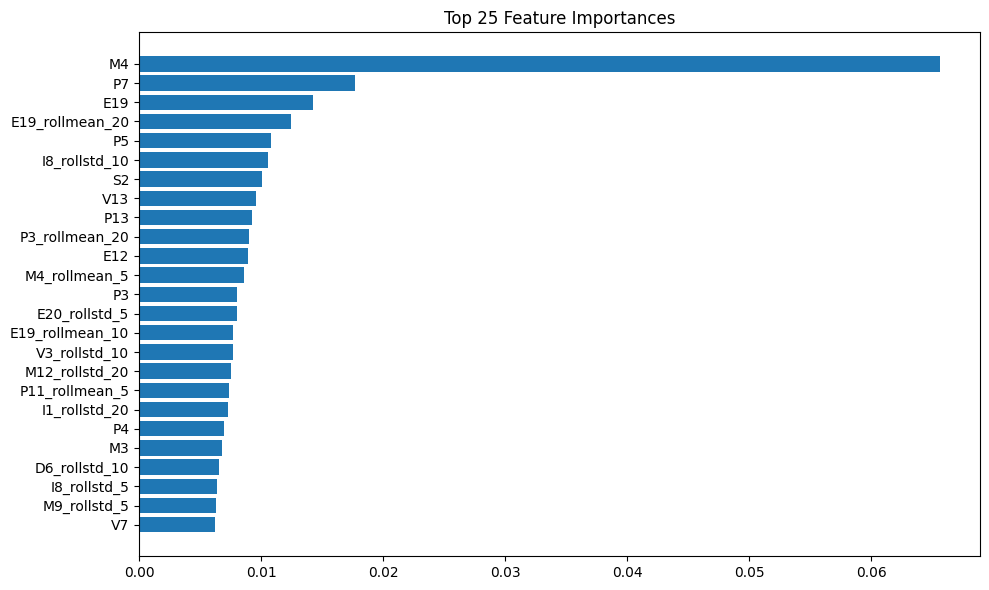

In [9]:
# Feature Importance

importance = np.mean(
    [model.feature_importance(importance_type="gain") for model in models], axis=0
)
feat_imp = pd.DataFrame({"feature": features, "importance": importance})
feat_imp = feat_imp.sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp.feature[:25][::-1], feat_imp.importance[:25][::-1])
plt.title("Top 25 Feature Importances")
plt.tight_layout()
plt.show()

In [10]:
# Test Predictions
test_preds = np.mean([model.predict(X_test_scaled) for model in models], axis=0)
print("Test predictions shape:", test_preds.shape)
print(test_preds[:10])  # Print first 10 predictions for verification

# Clip and normalize to valid allocation range (0–2)
allocations = np.clip(1 + test_preds, 0, 2)

Test predictions shape: (10,)
[-0.00048378 -0.00043656 -0.00027077 -0.00046706 -0.00040257 -0.00048705
 -0.00052813 -0.00044431 -0.00042527 -0.00045332]


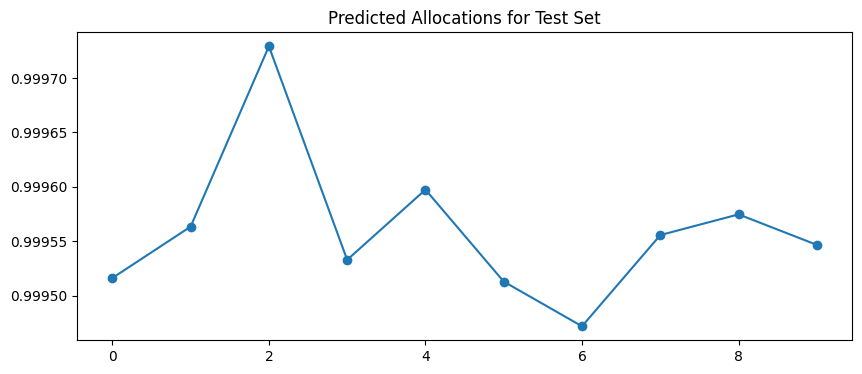

In [12]:
# visualize predictions
plt.figure(figsize=(10, 4))
plt.plot(allocations, marker='o')
plt.title("Predicted Allocations for Test Set")
plt.show()

In [11]:
# Submission
submission = pd.DataFrame({
    "date_id": test["date_id"],
    "allocation": allocations
})
print(submission)
submission.to_csv("submission.csv", index=False)
print("\nsubmission.csv saved successfully.")

   date_id  allocation
0     8980    0.999516
1     8981    0.999563
2     8982    0.999729
3     8983    0.999533
4     8984    0.999597
5     8985    0.999513
6     8986    0.999472
7     8987    0.999556
8     8988    0.999575
9     8989    0.999547

submission.csv saved successfully.
